In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import pandas as pd
from datetime import datetime, date

In [2]:
# Choose a variable:

ds = xr.load_dataset("../Part1_analysis/ERA5_features/grib_files/u10_50_87.grib", engine="cfgrib")
var_daily1 = ds.u.groupby(ds.u.time.dt.date).mean()

Ignoring index file '../Part1_analysis/ERA5_features/grib_files/u10_50_87.grib.5b7b6.idx' incompatible with GRIB file


In [3]:
# Choose a variable:

ds = xr.load_dataset("../Part1_analysis/ERA5_features/grib_files/u10_88_25.grib", engine="cfgrib")
var_daily2 = ds.u.groupby(ds.u.time.dt.date).mean()

Ignoring index file '../Part1_analysis/ERA5_features/grib_files/u10_88_25.grib.5b7b6.idx' incompatible with GRIB file


In [4]:
var_daily = xr.concat([var_daily1, var_daily2], dim='date')

In [5]:
dates = var_daily.date.data
datetimes = np.zeros_like(dates)
for i in range(len(dates)):
    datetimes[i] = datetime.combine(dates[i], datetime.min.time())

In [6]:
var_daily.coords["time"] = ("date", datetimes)
var_daily = var_daily.swap_dims({"date": "time"})
var_daily = var_daily.reset_coords('date', drop=True)

In [7]:
var_daily = var_daily.reset_coords(['number', 'step', 'isobaricInhPa'], drop=True)
var_daily = var_daily.sel(time=slice("1950-07", "2025-06"))
month = var_daily.time.dt.month
day = var_daily.time.dt.day
var_daily = var_daily.sel(time=~((month == 2) & (day == 29)))
var_daily = var_daily.assign_coords({'month_day': 31*var_daily['time.month'] + var_daily['time.day']})

In [8]:
var_7dMean = var_daily.rolling(time=7, min_periods=7, center=True).mean()
month = var_7dMean.time.dt.month
day = var_7dMean.time.dt.day
var_7dMean = var_7dMean.sel(time=~( ((month==10)&(day<4)) | ((month==2)&(day>25)) ))

In [9]:
weights = np.cos(np.deg2rad(var_daily.latitude))
weights.name = "weights"

In [10]:
var_7dMean_regmean = var_7dMean.weighted(weights).mean(dim=['longitude', 'latitude'])
var_7dMean_regstd = var_7dMean.weighted(weights).std(dim=['longitude', 'latitude'])
var_7dMean_regmin = var_7dMean.min(dim=['longitude', 'latitude'])
var_7dMean_regmax = var_7dMean.max(dim=['longitude', 'latitude'])

In [11]:
var_7dMean_regmean_anom = var_7dMean_regmean.groupby('month_day') - var_7dMean_regmean.sel(time=slice("1950-07", "2010-06")).groupby('month_day').mean()
var_7dMean_regstd_anom = var_7dMean_regstd.groupby('month_day') - var_7dMean_regstd.sel(time=slice("1950-07", "2010-06")).groupby('month_day').mean()
var_7dMean_regmin_anom = var_7dMean_regmin.groupby('month_day') - var_7dMean_regmin.sel(time=slice("1950-07", "2010-06")).groupby('month_day').mean()
var_7dMean_regmax_anom = var_7dMean_regmax.groupby('month_day') - var_7dMean_regmax.sel(time=slice("1950-07", "2010-06")).groupby('month_day').mean()

In [12]:
# Choose appropriate names:

df_var = var_7dMean_regmean_anom.to_dataframe(name='u10_mean')
df_var['u10_std'] = var_7dMean_regstd_anom.to_dataframe()['u']
df_var['u10_min'] = var_7dMean_regmin_anom.to_dataframe()['u']
df_var['u10_max'] = var_7dMean_regmax_anom.to_dataframe()['u']

In [13]:
df_var = df_var.drop(['month_day'], axis=1)
month = df_var.index.month
day = df_var.index.day
df_var_week3 = df_var[((month == 11) & (day >= 13)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 4))]
df_var_week4 = df_var[((month == 11) & (day >= 6)) | (month == 12) | ((month == 1) & (day <= 28))]

In [14]:
df_var_week3

,u10_mean,u10_std,u10_min,u10_max
time,,,,
1950-11-13,-0.660111,-4.606837,-0.785998,-8.867844
1950-11-14,-0.910321,-4.688998,0.575653,-12.286896
1950-11-15,-1.221206,-4.456774,0.905411,-13.279629
1950-11-16,-1.461497,-4.056197,2.177732,-11.757511
1950-11-17,-1.721555,-3.564465,3.657738,-10.716717
...,...,...,...,...
2025-01-31,12.758697,3.098316,-0.197412,12.584007
2025-02-01,13.466350,2.533620,1.240541,12.338589
2025-02-02,13.920874,2.190542,2.472509,11.193378


<Axes: xlabel='time'>

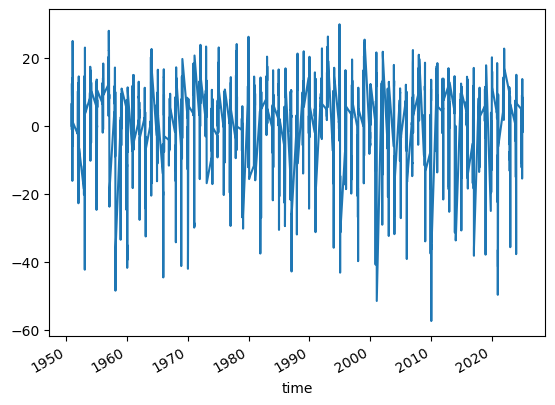

In [18]:
df_var_week3['u10_min'].plot()

In [19]:
# Name files appropriately:

df_var_week3.to_csv('u10_week3.csv')
df_var_week4.to_csv('u10_week4.csv')